# Taller 1 · ¿Hasta dónde sirve el modelo del balancín?

**Control Inteligente II (168418) · Universidad de Pamplona**
Docente: Ing. Jeisson Martínez Flórez · Viernes 23 de octubre de 2026

---

Actividad **formativa**, sin nota. Trabaje con su equipo de proyecto.

**Qué va a hacer.** Va a simular el robot balancín que construyeron este semestre. Va a medir en cuánto
tiempo se cae sin control, va a encontrar el polo inestable de la planta y va a determinar hasta qué
ángulo el *modelo linealizado* sigue siendo válido. Esos tres números son importantes para el resto de temas que vamos a ver.

**Requisitos.** Solo `numpy` y `matplotlib`. Si no tiene Python instalado, abra el cuaderno en Google
Colab (Archivo → Subir cuaderno) y ejecútelo allí sin instalar nada.

**Entregable de la actividad.** La tabla del paso 5 diligenciada y las tres respuestas del paso 6, en
este mismo cuaderno. Se comparte por el grupo de WhatsApp.

---
## 0. El modelo

Coordenadas: `x` es la posición del eje de las ruedas y `th` (θ) la inclinación del cuerpo respecto
a la vertical. θ = 0 es el robot en pie. La entrada es el par total `tau` que los motores aplican
entre las ruedas y el cuerpo.

Ecuaciones de Lagrange del péndulo invertido de dos ruedas, plano y sin deslizamiento:

$$A\,\ddot{x} + B\cos\theta\,\ddot{\theta} - B\sin\theta\,\dot{\theta}^2 = \frac{\tau}{r}$$

$$C\,\ddot{\theta} + B\cos\theta\,\ddot{x} - Bg\sin\theta = -\tau$$

con

$$A = 2m_w + \frac{2I_w}{r^2} + M_b \qquad B = M_b\,\ell \qquad C = I_b + M_b\,\ell^2$$

Ejecute la celda siguiente sin cambiar nada.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

G = 9.81  # m/s^2

# --- Datos medidos del balancin del equipo ---
mw  = 0.050    # masa de UNA rueda [kg]: 50 g medidos
r   = 0.033    # radio de rueda [m]: 33 mm medidos
Mb  = 0.750    # masa del cuerpo inclinable [kg]: 750 g medidos
l   = 0.062    # eje de ruedas al centro de masa [m]: 6.2 cm medidos

# Tiempo de caida medido: 0.712 s (promedio de 10 ensayos; ruedas instaladas).
# Tiempo promedio experimental: 0.712 s (10 ensayos, ruedas instaladas).
T_caida_exp = 0.712

# Estimacion de Ib ajustada por simulacion del modelo no lineal: se supone
# una perturbacion inicial pequena de 1 grado desde la vertical, velocidad
# angular inicial cero, y se mide hasta theta = 90 grados.
# Con esas hipotesis, Ib = 7.54e-3 kg m^2 reproduce aproximadamente 0.712 s.
# NO es una medicion directa: depende de la perturbacion inicial supuesta.
Ib  = 7.54e-3   # kg m^2, estimacion condicionada a theta0 = 1 grado

# Aproximacion: cada rueda es un disco macizo homogeneo.
Iw = 0.5 * mw * r**2

print('DATOS DEL ROBOT')
print(f'Mb = {Mb:.3f} kg; l = {l:.3f} m; mw = {mw:.3f} kg; r = {r:.3f} m')
print(f'Iw estimado por rueda = {Iw:.6e} kg·m²')
print(f'Ib estimado = {Ib:.6e} kg·m² (hipotesis: theta0 = 1 grado)')
print(f'Tiempo experimental de caida = {T_caida_exp:.3f} s (promedio de 10 ensayos)')

def coeficientes(Mb=Mb, mw=mw, r=r, l=l, Ib=Ib):
    Iw = 0.5 * mw * r**2
    A = 2*mw + 2*Iw/r**2 + Mb
    B = Mb * l
    C = Ib + Mb * l**2
    return A, B, C, A*C - B**2

A, B, C, D = coeficientes()
print(f"\nA = {A:.4f} kg      B = {B:.5f} kg·m")
print(f"C = {C:.3e} kg·m²   D = AC - B² = {D:.3e}")


DATOS DEL ROBOT
Mb = 0.750 kg; l = 0.062 m; mw = 0.050 kg; r = 0.033 m
Iw estimado por rueda = 2.722500e-05 kg·m²
Ib estimado = 7.540000e-03 kg·m² (hipotesis: theta0 = 1 grado)
Tiempo experimental de caida = 0.712 s (promedio de 10 ensayos)

A = 0.9000 kg      B = 0.04650 kg·m
C = 1.042e-02 kg·m²   D = AC - B² = 7.218e-03


Datos reales del equipo y estimación de la inercia
Datos medidos del balancín:
- Masa del cuerpo sin llantas: 750 g = 0.750 kg.
- Distancia del eje al centro de masa del cuerpo sin llantas: 6.2 cm = 0.062 m.
- Distancia medida al centro de masa del conjunto con llantas: 5.2 cm = 0.052 m.
- Masa de cada rueda: 50 g = 0.050 kg.
- Radio de cada rueda: 33 mm = 0.033 m.
- Tiempo promedio de caída: 0.712 s, obtenido de 10 ensayos con las llantas instaladas. El robot se soltó intentando mantenerlo vertical y se midió hasta tocar el suelo.
Distancia usada en el modelo: l = 0.062 m, porque Mb = 0.750 kg es la masa del cuerpo inclinable sin ruedas. Los 5.2 cm corresponden al conjunto con ruedas y no deben mezclarse con la masa del cuerpo sin ruedas.

La inercia de cada rueda se aproxima como disco macizo homogéneo: \(I_w=\frac12m_wr^2=2.7225\times10^{-5}\;\text{kg·m}^2\).

Estimación adoptada para este taller: se supone que, aunque visualmente se soltó vertical, existió una pequeña perturbación inicial de 1°, con velocidad angular inicial nula. Se ajustó Ib en el modelo no lineal para que el cuerpo pase de 1° a 90° en aproximadamente 0.712 s. Con las demás magnitudes medidas se obtiene Ib ≈ 0.00754 kg·m².



---
## 1. El modelo no lineal y el integrador

`f_nolineal` despeja las dos aceleraciones resolviendo el sistema 2×2 de arriba. `rk4` es un
integrador de Runge-Kutta de cuarto orden.
> Este método es usado para resolver ecuaciones diferenciales ordinarias con un valor inicial dado. En el modelo del balancín, las ecuaciones de movimiento se expresan como ecuaciones diferenciales complejas (en `f_nolineal`) el integrador Runge-Kutta toma el estado actual del robot (posición, velocidad, ángulo, velocidad angular) y avanza en el tiempo en pequeños pasos (h). Para cada paso, calcula la "pendiente" o derivada en varios puntos intermedios (k1, k2, k3, k4) y toma un promedio ponderado para estimar cuál será el estado del robot en el siguiente instante (hacia donde va). Así se puede "simular" fácilmente la física del robot a lo largo del tiempo.

Ejecute la celda y observe la forma de la caída.

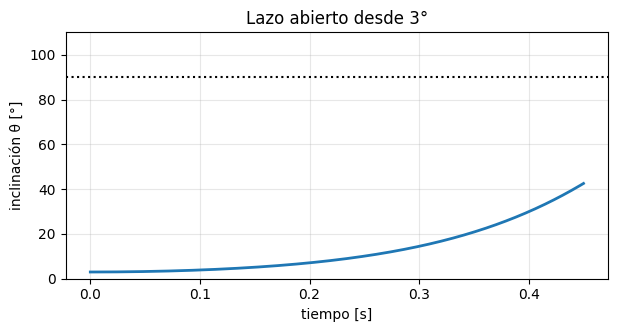

In [8]:
def f_nolineal(s, tau=0.0, Mb=Mb):
    """s = [x, xdot, th, thdot]  ->  derivada del estado."""
    A, B, C, _ = coeficientes(Mb=Mb)        # Obtiene parámetros
    x, xd, th, thd = s                      # Desempaqueta el vector de estado
    ct, st = np.cos(th), np.sin(th)         # Calcula coseno y seno
    M = np.array([[A,    B*ct],             # Construye matriz de inercia
                  [B*ct, C   ]])
    b = np.array([tau/r + B*st*thd**2,      # Construye vector de fuerzas ext
                  -tau  + B*G*st])
    xdd, thdd = np.linalg.solve(M, b)       # Resuelve el sistema de EcuLineal
    return np.array([xd, xdd, thd, thdd])

def rk4(f, s0, t, **kw):                            # Parámetros de entrada: f=f_nolineal , s0=estado inicial, t=instantes de tiempo, **kw=argumentos extra
    s = np.zeros((len(t), len(s0))); s[0] = s0      # Prepara matriz para guardar estados del robot
    for k in range(len(t)-1):                       # Avance paso a paso
        h = t[k+1] - t[k]                           # Calcula tamaño del paso de tiempo actual
        k1 = f(s[k],          **kw)                 # Evalúa la derivada del vector de estado actual y subpasos
        k2 = f(s[k] + h/2*k1, **kw)
        k3 = f(s[k] + h/2*k2, **kw)
        k4 = f(s[k] + h*k3,   **kw)
        s[k+1] = s[k] + h/6*(k1 + 2*k2 + 2*k3 + k4) # Calcula el estado del robot en el siguiente instante de tiempo
    return s

# Vector de tiempo para la simulación | Deste 0->0.45 con 451 puntos
t = np.linspace(0, 0.45, 451)

''' Explicación de 's':
Ejecuta la simulación con las funciones rk4 y f_nolineal.
Argumentos:
- f_nolineal = que contiene el modelo del robot.
- [0, 0, np.radians(3), 0] = es el vector del estado inicial. Posición 0. Velocidad 0. Ángulo de 3 grados (en radianes). Velocidad angular 0.
- t = vector de tiempo.
'''
s = rk4(f_nolineal, [0, 0, np.radians(3), 0], t)

# Gráfico
plt.figure(figsize=(7, 3.2))
plt.plot(t, np.degrees(s[:, 2]), lw=2)                 # Curva azul de ángulo del robot según simulación
plt.axhline(90, ls=":", color="k")                     # Línea negra que indica 90º = robot cae al suelo
plt.xlabel("tiempo [s]"); plt.ylabel("inclinación θ [°]"); plt.ylim(0, 110)
plt.title("Lazo abierto desde 3°"); plt.grid(alpha=.3); plt.show()


### Paso 1 · Tiempo de caída

Complete la función. `t_caida` debe devolver el instante en el que θ llega a 90°, es decir, cuando
el robot ya está acostado.

In [9]:
def t_caida(th0_grados, Mb=Mb, t_max=2.0):
    t = np.linspace(0, t_max, 4001)
    s = rk4(f_nolineal, [0, 0, np.radians(th0_grados), 0], t, Mb=Mb)
    th = np.degrees(s[:, 2])
    indices = np.flatnonzero(th >= 90)
    if len(indices) == 0:
        return np.nan
    k = indices[0]
    return t[k]

# Comparacion con el ensayo: la condicion inicial de 1 grado es una hipotesis.
for th0 in [1, 3, 5]:
    print(f"θ0 = {th0}°  ->  cae en {1000*t_caida(th0):.0f} ms")
print(f"Tiempo experimental promedio = {1000*T_caida_exp:.0f} ms")

θ0 = 1°  ->  cae en 712 ms
θ0 = 3°  ->  cae en 567 ms
θ0 = 5°  ->  cae en 499 ms
Tiempo experimental promedio = 712 ms


---
## 2. El modelo linealizado

Alrededor de θ = 0, con θ pequeño y θ̇ ≈ 0, se toma sen θ ≈ θ, cos θ ≈ 1 y θ̇² ≈ 0. El sistema queda

$$\begin{bmatrix} A & B \\ B & C\end{bmatrix}
\begin{bmatrix}\ddot{x}\\ \ddot{\theta}\end{bmatrix}
= \begin{bmatrix}\tau/r \\ Bg\theta - \tau\end{bmatrix}$$

y despejando se llega al espacio de estados con $\mathbf{x} = [x,\ \dot{x},\ \theta,\ \dot{\theta}]^T$
y $u = \tau$.

### Paso 2 · Complete la matriz de estado

Los dos huecos son los términos que multiplican a θ en las filas de ẍ y de θ̈. Salen de resolver
el sistema de arriba con τ = 0, usando D = AC − B².

In [10]:
def espacio_estados(Mb=Mb):
    A, B, C, D = coeficientes(Mb=Mb)
    Am = np.array([[0, 1, 0,   0],
                   [0, 0, -B**2 * G / D, 0],  # ẍ = -(B²g/D) θ cuando τ = 0
                   [0, 0, 0,   1],
                   [0, 0, A*B * G / D, 0]])  # θ̈ = (ABg/D) θ cuando τ = 0
    Bm = np.array([0.0, (C/r + B)/D, 0.0, -(A + B/r)/D])
    return Am, Bm

Am, Bm = espacio_estados()
print("A =\n", np.round(Am, 3))
print("\nB =", np.round(Bm, 2))
print("\nvalores propios:", np.round(np.linalg.eigvals(Am), 3))

A =
 [[ 0.     1.     0.     0.   ]
 [ 0.     0.    -2.939  0.   ]
 [ 0.     0.     0.     1.   ]
 [ 0.     0.    56.875  0.   ]]

B = [   0.     50.2     0.   -319.89]

valores propios: [ 0.     0.     7.542 -7.542]


### Paso 3 · El polo inestable y el periodo de muestreo

El valor propio positivo `p` es el que hace caer al robot. Su inverso `1/p` es la constante de
tiempo de la caída.

Regla práctica de control digital: el lazo debe muestrear al menos **20 veces** dentro de una
constante de tiempo del modo más rápido de la planta.

In [11]:
p = max(np.linalg.eigvals(Am).real)
print(f"polo inestable        p    = +{p:.3f} rad/s")
print(f"constante de tiempo   1/p  = {1000/p:.1f} ms")

# Muestrear 20 veces por constante de tiempo: Ts <= (1/p)/20.
Ts_ms = 1000 / (20 * p)
print(f"periodo de muestreo   Ts  <= {Ts_ms:.2f} ms")

polo inestable        p    = +7.542 rad/s
constante de tiempo   1/p  = 132.6 ms
periodo de muestreo   Ts  <= 6.63 ms


---
## 3. ¿Hasta dónde sirve la linealización?

Con τ = 0 y θ̇ = 0, los dos modelos predicen aceleraciones angulares distintas:

$$\ddot{\theta}_{\text{no lineal}} = \frac{ABg\sin\theta}{AC - B^2\cos^2\theta}
\qquad
\ddot{\theta}_{\text{lineal}} = \frac{ABg\,\theta}{D}$$

### Paso 4 · Mida el error

In [12]:
def thdd_nolineal(th, Mb=Mb):
    A, B, C, _ = coeficientes(Mb=Mb)
    return A*B*G*np.sin(th) / (A*C - B**2*np.cos(th)**2)

def thdd_lineal(th, Mb=Mb):
    A, B, C, D = coeficientes(Mb=Mb)
    return A*B*G*th / D

def error_pct(th_grados):
    th = np.radians(th_grados)
    return 100*(thdd_lineal(th) - thdd_nolineal(th))/thdd_nolineal(th)

for d in [1, 2, 5, 10, 15, 20, 30, 45]:
    print(f"θ = {d:3d}°   error = {error_pct(d):6.2f} %")

θ =   1°   error =   0.01 %
θ =   2°   error =   0.06 %
θ =   5°   error =   0.35 %
θ =  10°   error =   1.42 %
θ =  15°   error =   3.18 %
θ =  20°   error =   5.64 %
θ =  30°   error =  12.56 %
θ =  45°   error =  27.71 %


5 %  de error a los 18.8°
10 % de error a los 26.7°


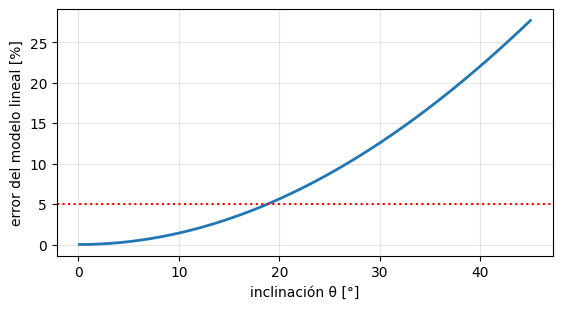

In [13]:
# Barrido: ¿en qué ángulo el error llega al 5 %?

d = np.linspace(0.1, 45, 900)
e = np.array([error_pct(x) for x in d])
print(f"5 %  de error a los {d[np.argmax(e > 5)]:.1f}°")
print(f"10 % de error a los {d[np.argmax(e > 10)]:.1f}°")

plt.figure(figsize=(6.4, 3.2))
plt.plot(d, e, lw=2); plt.axhline(5, ls=":", color="r")
plt.xlabel("inclinación θ [°]"); plt.ylabel("error del modelo lineal [%]")
plt.grid(alpha=.3); plt.show()

---
## 4. Cambie el robot y cambia el modelo

El día de la competencia el robot puede que cambie la masa por agregados y mejoras en el diseño mecánico y estructural. Analice qué efecto tiene esto.

In [14]:
for carga in [0.0, 0.15, 0.30, 0.60]:
    Am_c, _ = espacio_estados(Mb=Mb + carga)
    p_c = max(np.linalg.eigvals(Am_c).real)
    print(f"carga +{1000*carga:4.0f} g   ->   p = {p_c:6.3f} rad/s   "
          f"1/p = {1000/p_c:5.1f} ms   caída desde 3° = {1000*t_caida(3, Mb=Mb+carga):.0f} ms")

carga +   0 g   ->   p =  7.542 rad/s   1/p = 132.6 ms   caída desde 3° = 567 ms
carga + 150 g   ->   p =  8.254 rad/s   1/p = 121.1 ms   caída desde 3° = 521 ms
carga + 300 g   ->   p =  8.910 rad/s   1/p = 112.2 ms   caída desde 3° = 486 ms
carga + 600 g   ->   p = 10.094 rad/s   1/p =  99.1 ms   caída desde 3° = 434 ms


---
## 5. Tabla de resultados

Diligencie la tabla con los números que obtuvo. Este es el entregable de la sesión.

| Magnitud | Valor | Unidad |
|---|---|---|
| Tiempo experimental promedio de caída (10 ensayos) | 0.712 | s |
| Inercia estimada del cuerpo Ib | 0.00754 | kg·m² |
| Tiempo simulado desde θ₀ = 1° | 712 | ms |
| Tiempo de caída desde θ₀ = 3°, robot vacío | 567 | ms |
| Polo inestable p, robot vacío | 7.542 | rad/s |
| Periodo de muestreo máximo Ts | 6.63 | ms |
| Ángulo con 5 % de error del modelo lineal | 18.8 | ° |
| Polo inestable p con 300 g de carga | 8.910 | rad/s |

---
## 6. Tres preguntas

Responda en dos o tres frases cada una.

**6.1** El ESP32-S3 corre a 240 MHz. Con el periodo de muestreo que calculó, ¿cuántos ciclos de reloj
tiene el microcontrolador para leer la IMU, estimar el ángulo, calcular el control y escribir el PWM?
¿Le parece suficiente o está "apretado" o "corta" esa frecuencia?

**6.2** El controlador PID (o LQR en próxima clase) que van a diseñar en la se calcula a partir del modelo
**lineal**. Según lo que midió en el paso 4, ¿en qué rango de inclinación puede confiar en ese
controlador? ¿Qué pasa si el robot recibe un golpe que lo saca de ese rango?

**6.3** Los valores de `Mb`, `l` e `Ib` que aparecen al principio son estimados y generales. Debe actualizarlos con los de su propio robot. Registre acá cómo los calculó o los obtuvo.

**6.1** _Con el periodo máximo de muestreo calculado (Ts ≈ 6.63 ms), un microcontrolador a 240 MHz dispone de aproximadamente 240×10⁶ × 0.00663 ≈ 1 591 200 ciclos de reloj por muestra. En principio es suficiente para un PID o LQR sencillo, pero debe medirse el tiempo real de ejecución incluyendo lectura de IMU, estimación, comunicaciones e interrupciones._

**6.2** _Con la estimación actual de Ib, el error del modelo lineal alcanza el 5 % aproximadamente a los 18.8° respecto a la vertical. Cerca de la posición vertical la aproximación lineal es razonable; al aumentar la inclinación, el error crece y el modelo no lineal representa mejor la dinámica._

**6.3** _Se midieron Mb = 0.750 kg, l = 0.062 m, mw = 0.050 kg, r = 0.033 m y un tiempo de caída promedio de 0.712 s en 10 ensayos. Para estimar la inercia se supuso una perturbación inicial de 1° y se ajustó el modelo no lineal, obteniendo Ib ≈ 0.00754 kg·m². Este resultado es condicionado a esa hipótesis, ya que no se midió la inclinación inicial real._

---
## Criterios de éxito

La actividad está lograda si al terminar la sesión su equipo puede:

1. Ejecutar el cuaderno completo sin errores.
2. Justificar de dónde sale cada uno de los dos coeficientes que completó en la matriz de estado.
3. Justificar por qué el periodo de muestreo del balancín no puede ser de 50 ms.
4. Nombrar el rango de inclinación en el que el modelo lineal es utilizable y decir qué observó
   fuera de ese rango.
5. Explicar por qué añadir carga al cuerpo cambia el polo inestable.

---
*Control Inteligente II – Ing. Jeisson Martínez Flórez*